<a href="https://colab.research.google.com/github/KrithikChidM/PrmlLab/blob/main/Lab7/code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Qn1

In [ ]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)

n = 5000
K = 3
weights = np.array([0.5, 0.3, 0.2])

In [ ]:
means = np.array([[-1.0, -3.5], [0.0, 0.0], [1.0, 3.5]])
means_2 = means + np.array([4.0, 0.0])
class_means = [means, means_2]

covariances = [
    np.array([[1.0, 0.6], [0.6, 1.0]]),
    np.eye(2),
    np.diag([1.5, 0.5])
]

covariances_2 = [
    np.array([[1.0, -0.6], [-0.6, 1.0]]),
    np.eye(2),
    np.array([[1.5, -0.5], [-0.5, 0.5]])
]

class_covariances = [covariances, covariances_2]

covariance_names = [
    ["Full (+tilt)", "Isotropic", "Diagonal"],
    ["Full (-tilt)", "Isotropic", "Full (-tilt)"]
]

In [ ]:
def uniform():
    return max(random.random(), 1e-12)

def box_muller():
    u1 = uniform()
    u2 = uniform()
    r = math.sqrt(-2 * math.log(u1))
    theta = 2 * math.pi * u2
    z1 = r * math.cos(theta)
    z2 = r * math.sin(theta)
    return z1, z2

In [ ]:
def generate_component(mean, C):
    z1, z2 = box_muller()

    a, b = C[0]
    c, d = C[1]

    l11 = math.sqrt(a)
    l21 = c / l11
    l22 = math.sqrt(max(d - l21*l21, 0.0))

    x1 = mean[0] + l11*z1
    x2 = mean[1] + l21*z1 + l22*z2

    return [x1, x2]

In [ ]:
def generate_gmm_data(means, covariances, weights, n):
    X = []
    component_labels = []

    for _ in range(n):
        u = uniform()

        if u < weights[0]:
            k = 0
        elif u < weights[0] + weights[1]:
            k = 1
        else:
            k = 2

        x = generate_component(means[k], covariances[k])

        X.append(x)
        component_labels.append(k)

    return np.array(X), np.array(component_labels)

In [ ]:
class_data = []
class_component_labels = []

for cls in range(2):
    X, component_labels = generate_gmm_data(
        class_means[cls],
        class_covariances[cls],
        weights,
        n
    )

    class_data.append(X)
    class_component_labels.append(component_labels)

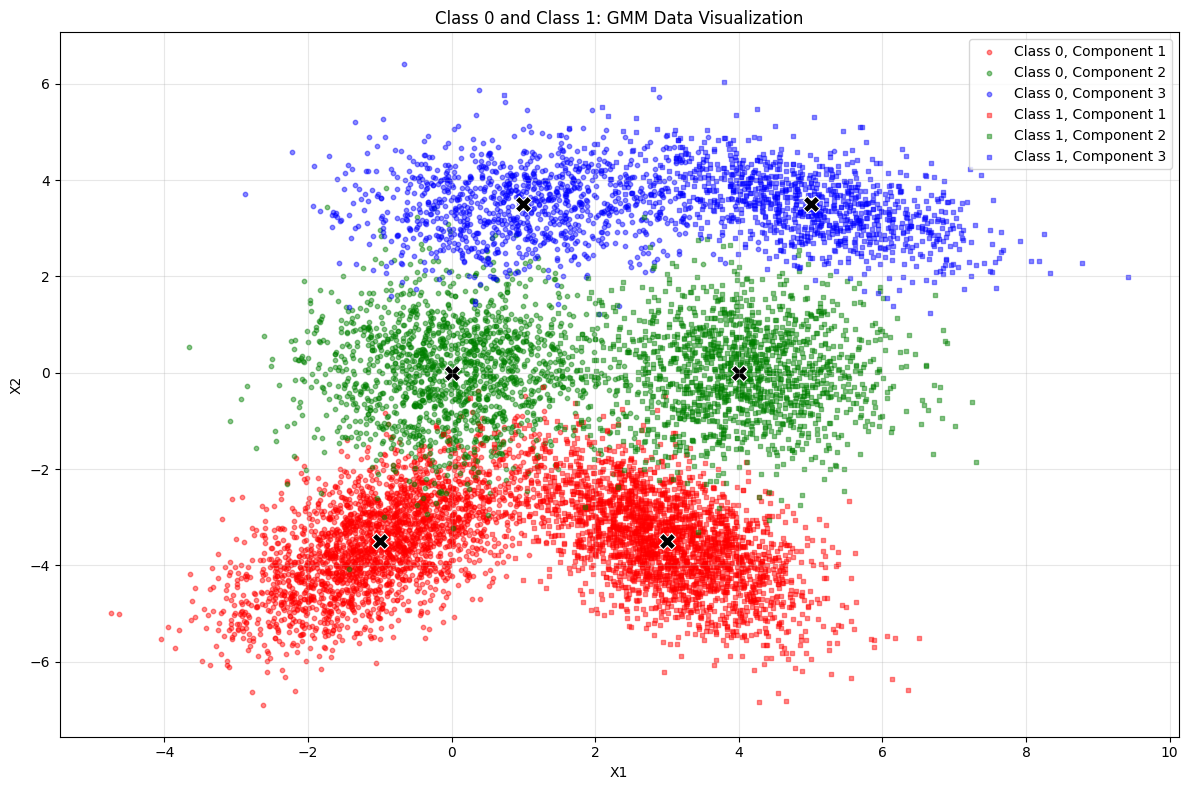

In [ ]:
plt.figure(figsize=(12, 8))

colors = ["red", "green", "blue"]
markers = ["o", "s"]

for cls in range(2):
    X = class_data[cls]
    labels = class_component_labels[cls]

    for k in range(K):
        points = X[labels == k]
        plt.scatter(
            points[:, 0], points[:, 1],
            color=colors[k], marker=markers[cls],
            s=10, alpha=0.45,
            label=f"Class {cls}, Component {k + 1}"
        )

    for k in range(K):
        plt.scatter(
            class_means[cls][k][0], class_means[cls][k][1],
            color="black", marker="X", s=140,
            edgecolors="white", linewidths=0.8
        )

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Class 0 and Class 1: GMM Data Visualization")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
train_data = []
test_data = []

rng = np.random.default_rng(44)
train_end = int(0.8 * n)

for samples in class_data:
    shuffled = samples[np.random.default_rng().permutation(n)]
    train_data.append(shuffled[:train_end])
    test_data.append(shuffled[train_end:])

In [ ]:
class GMM:
    def __init__(self, K, max_iterations=100, tolerance=1e-5):
        self.K = K
        self.max_iterations = max_iterations
        self.tolerance = tolerance

    def gaussian_density(self, X, mean, covariance):
        dimension = X.shape[1]

        a = covariance[0, 0]
        b = covariance[0, 1]
        c = covariance[1, 0]
        d = covariance[1, 1]

        det = a * d - b * c

        if det <= 1e-12:
            return np.zeros(len(X))

        dx = X[:, 0] - mean[0]
        dy = X[:, 1] - mean[1]

        q = (d * dx**2 - (b + c) * dx * dy + a * dy**2) / det

        return np.exp(-0.5 * q) / (
            (2 * math.pi) ** (dimension / 2) * math.sqrt(det)
        )

    def initialize(self, X):
        self.means = np.array(random.sample(list(X), self.K))

        self.weights = np.ones(self.K) / self.K

        self.covariances = []

        for i in range(self.K):
            self.covariances.append(np.eye(X.shape[1]))

        self.covariances = np.array(self.covariances)

    def expectation(self, X):
        responsibilities = np.zeros((len(X), self.K))

        for k in range(self.K):
            responsibilities[:, k] = (
                self.weights[k] *
                self.gaussian_density(
                    X, self.means[k], self.covariances[k]
                )
            )

        total = np.sum(responsibilities, axis=1, keepdims=True)
        total = np.maximum(total, 1e-300)

        responsibilities = responsibilities / total

        return responsibilities

    def maximization(self, X, responsibilities):
        Nk = np.sum(responsibilities, axis=0)
        Nk = np.maximum(Nk, 1e-10)

        self.weights = Nk / len(X)

        self.means = (
            responsibilities.T @ X
        ) / Nk[:, None]

        self.covariances = []

        for k in range(self.K):
            difference = X - self.means[k]

            covariance = (
                responsibilities[:, k][:, None] * difference
            ).T @ difference / Nk[k]

            covariance += np.eye(X.shape[1]) * 1e-6

            self.covariances.append(covariance)

        self.covariances = np.array(self.covariances)

    def fit(self, X):
        self.initialize(X)

        previous_log_likelihood = -float("inf")

        for iteration in range(self.max_iterations):
            responsibilities = self.expectation(X)

            self.maximization(X, responsibilities)

            likelihood = np.zeros(len(X))

            for k in range(self.K):
                likelihood += (
                    self.weights[k] *
                    self.gaussian_density(
                        X, self.means[k], self.covariances[k]
                    )
                )

            log_likelihood = np.sum(
                np.log(np.maximum(likelihood, 1e-300))
            )

            if abs(log_likelihood - previous_log_likelihood) < self.tolerance:
                break

            previous_log_likelihood = log_likelihood

    def predict_density(self, X):
        density = np.zeros(len(X))

        for k in range(self.K):
            density += (
                self.weights[k] *
                self.gaussian_density(
                    X, self.means[k], self.covariances[k]
                )
            )

        return density

    def predict(self, X):
        return np.log(np.maximum(self.predict_density(X), 1e-300))

In [ ]:
gmm_models = []

for cls in range(2):
    model = GMM(K=K, max_iterations=200)
    model.fit(train_data[cls])

    gmm_models.append(model)

    print(f"\nClass {cls} GMM Model")
    print("Weights:", model.weights)
    print("Means:\n", model.means)
    print("Covariances:\n", model.covariances)


Class 0 GMM Model
Weights: [0.30146887 0.49243937 0.20609176]
Means:
 [[ 0.00541461  0.026117  ]
 [-0.99353148 -3.51424585]
 [ 1.02574664  3.49726011]]
Covariances:
 [[[1.02465693 0.05718701]
  [0.05718701 1.05495558]]

 [[0.98340169 0.60997597]
  [0.60997597 1.0420455 ]]

 [[1.52688346 0.0281757 ]
  [0.0281757  0.51656337]]]

Class 1 GMM Model
Weights: [0.28763245 0.20379107 0.50857648]
Means:
 [[ 4.04580562  0.02846296]
 [ 4.94943771  3.4949598 ]
 [ 3.01086462 -3.48900918]]
Covariances:
 [[[ 1.11842946 -0.00156449]
  [-0.00156449  0.95747166]]

 [[ 1.53342316 -0.49894656]
  [-0.49894656  0.51305042]]

 [[ 0.94016063 -0.5430826 ]
  [-0.5430826   0.95412445]]]


In [ ]:
actual_labels = []
predicted_labels = []

for cls in range(2):
    for point in test_data[cls]:
        point = np.array(point).reshape(1, -1)

        density0 = gmm_models[0].predict(point)[0]
        density1 = gmm_models[1].predict(point)[0]

        predicted_class = 0 if density0 > density1 else 1

        actual_labels.append(cls)
        predicted_labels.append(predicted_class)

actual_labels = np.array(actual_labels)
predicted_labels = np.array(predicted_labels)

correct = np.sum(actual_labels == predicted_labels)
total = len(actual_labels)

print("Total test samples:", total)
print("Correct predictions:", correct)
print("Incorrect predictions:", total - correct)
print(f"Classification Accuracy: {100 * correct / total:.2f}%")

Total test samples: 2000
Correct predictions: 1946
Incorrect predictions: 54
Classification Accuracy: 97.30%


In [ ]:
confusion_matrix = np.zeros((2, 2), dtype=int)

for actual, predicted in zip(actual_labels, predicted_labels):
    confusion_matrix[actual][predicted] += 1

print("Confusion Matrix:")
print(confusion_matrix)

print("\nRows = Actual Classes")
print("Columns = Predicted Classes")
print("             Predicted 0    Predicted 1")
print("Actual 0       ", confusion_matrix[0, 0], "          ", confusion_matrix[0, 1])
print("Actual 1       ", confusion_matrix[1, 0], "          ", confusion_matrix[1, 1])

Confusion Matrix:
[[977  23]
 [ 31 969]]

Rows = Actual Classes
Columns = Predicted Classes
             Predicted 0    Predicted 1
Actual 0        977            23
Actual 1        31            969


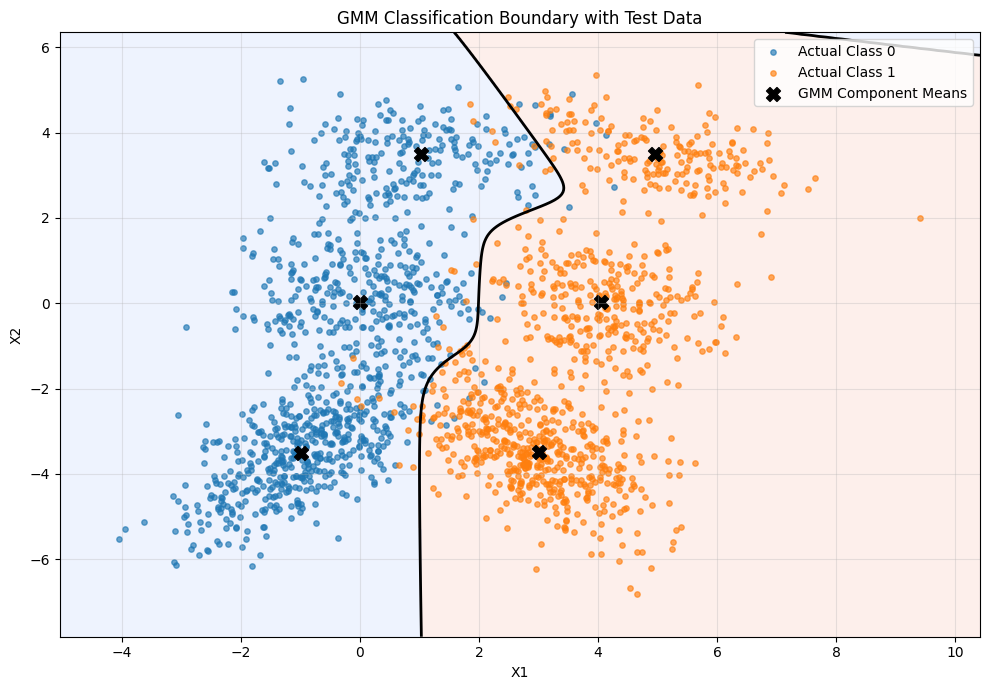

In [ ]:
plt.figure(figsize=(10, 7))

all_test = np.vstack(test_data)

x_min = all_test[:, 0].min() - 1
x_max = all_test[:, 0].max() + 1
y_min = all_test[:, 1].min() - 1
y_max = all_test[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.column_stack((xx.ravel(), yy.ravel()))

density0 = np.exp(gmm_models[0].predict(grid))
density1 = np.exp(gmm_models[1].predict(grid))

Z = (density1 > density0).astype(int).reshape(xx.shape)

plt.contourf(
    xx, yy, Z,
    levels=[-0.5, 0.5, 1.5],
    alpha=0.15,
    cmap="coolwarm"
)

plt.contour(
    xx, yy,
    density0.reshape(xx.shape) - density1.reshape(xx.shape),
    levels=[0],
    colors="black",
    linewidths=2
)

for cls in range(2):
    X = test_data[cls]

    plt.scatter(
        X[:, 0], X[:, 1],
        s=15,
        alpha=0.65,
        label=f"Actual Class {cls}"
    )

plt.scatter(
    np.vstack([model.means for model in gmm_models])[:, 0],
    np.vstack([model.means for model in gmm_models])[:, 1],
    color="black",
    marker="X",
    s=100,
    label="GMM Component Means"
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("GMM Classification Boundary with Test Data")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#Qn2

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

base_path = '/content/drive/MyDrive/Krithik SNU/HAM/teams/TEAM_7/train'

digits = [6, 3, 8]
K_values = [3 ,6, 9]
max_iter = 50
eps = 1e-10
rng = np.random.default_rng(42)

Mounted at /content/drive


In [2]:
def get_image_files(folder):
    extensions = ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')
    files = []

    for root, dirs, names in os.walk(folder):
        dirs.sort()
        for name in sorted(names):
            if name.lower().endswith(extensions):
                files.append(os.path.join(root, name))

    return files
def load_image(filename):
    img = mpimg.imread(filename)

    if img.ndim == 3:
        img = img[:, :, :3].mean(axis=2)

    img = img.astype(np.float64)

    if img.max() > 1:
        img /= 255.0

    h, w = img.shape
    rows = np.linspace(0, h - 1, 28).astype(int)
    cols = np.linspace(0, w - 1, 28).astype(int)

    return img[np.ix_(rows, cols)].reshape(784)

In [3]:
def logsumexp(a, axis=1):
    m = np.max(a, axis=axis, keepdims=True)
    return (
        m + np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True))
    ).squeeze(axis)

def log_gaussian_diag(X, means, variances):
    diff = X[:, None, :] - means[None, :, :]

    return -0.5 * (
        X.shape[1] * np.log(2 * np.pi)
        + np.sum(np.log(variances), axis=1)[None, :]
        + np.sum(diff ** 2 / variances[None, :, :], axis=2)
    )

def fit_gmm(X, K, max_iter=50):
    n, d = X.shape

    means = X[rng.choice(n, K, replace=False)].copy()
    global_var = np.var(X, axis=0) + 1e-4
    variances = np.tile(global_var, (K, 1))
    weights = np.ones(K) / K

    previous_ll = -np.inf

    for iteration in range(max_iter):
        log_prob = log_gaussian_diag(X, means, variances)
        log_joint = log_prob + np.log(weights + eps)
        log_norm = logsumexp(log_joint)

        responsibilities = np.exp(log_joint - log_norm[:, None])
        Nk = responsibilities.sum(axis=0) + eps

        weights = Nk / n
        means = responsibilities.T @ X / Nk[:, None]

        for k in range(K):
            diff = X - means[k]
            variances[k] = (
                responsibilities[:, k, None] * diff ** 2
            ).sum(axis=0) / Nk[k]

        variances = np.maximum(variances, 1e-4)

        current_ll = np.sum(log_norm)

        if abs(current_ll - previous_ll) < 1e-4:
            break

        previous_ll = current_ll

    return weights, means, variances

def score_gmm(X, model):
    weights, means, variances = model
    log_prob = log_gaussian_diag(X, means, variances)

    return logsumexp(
        log_prob + np.log(weights + eps)[None, :]
    )

def predict(X, models):
    scores = np.column_stack([
        score_gmm(X, models[d]) for d in digits
    ])

    return np.array(digits)[np.argmax(scores, axis=1)]

In [4]:
data = {}
for digit in digits:
    folder = os.path.join(base_path, str(digit))
    files = get_image_files(folder)

    print(f"\nDigit {digit}: Total images = {len(files)}")

    if len(files) < max(K_values):
        raise ValueError(f"Not enough images for digit {digit}")

    images = np.array([load_image(f) for f in files])
    rng.shuffle(images)

    split = int(0.8 * len(images))

    data[digit] = {
        'development': images[:split],
        'test': images[split:]
    }

    print("Development images:", split)
    print("Test images:", len(images) - split)


Digit 6: Total images = 4752
Development images: 3801
Test images: 951

Digit 3: Total images = 4886
Development images: 3908
Test images: 978

Digit 8: Total images = 4674
Development images: 3739
Test images: 935


In [5]:
train_data = {}
validation_data = {}
test_data = {}

for digit in digits:
    X = data[digit]['development']
    split = int(0.75 * len(X))

    train_data[digit] = X[:split]
    validation_data[digit] = X[split:]
    test_data[digit] = data[digit]['test']

    print(
        f"\nDigit {digit}: "
        f"Training={len(train_data[digit])}, "
        f"Validation={len(validation_data[digit])}, "
        f"Testing={len(test_data[digit])}"
    )


Digit 6: Training=2850, Validation=951, Testing=951

Digit 3: Training=2931, Validation=977, Testing=978

Digit 8: Training=2804, Validation=935, Testing=935


In [6]:
best_K = {}
validation_results = {}

for digit in digits:
    print(f"\n========== Digit {digit} ==========")

    results = []

    for K in K_values:
        print(f"Training GMM with K={K}")

        candidate_models = {}

        for d in digits:
            candidate_models[d] = fit_gmm(
                train_data[d], K, max_iter
            )

        X_val = np.vstack([
            validation_data[d] for d in digits
        ])

        y_val = np.concatenate([
            np.full(len(validation_data[d]), d)
            for d in digits
        ])

        y_pred = predict(X_val, candidate_models)

        accuracy = np.mean(y_pred == y_val)
        results.append(accuracy)

        print(f"K={K}, Validation Accuracy={accuracy * 100:.2f}%")

    best_index = np.argmax(results)
    best_K[digit] = K_values[best_index]
    validation_results[digit] = results

    print(f"Best K for digit {digit}: {best_K[digit]}")


========== Digit 6 ==========
Training GMM with K=3
K=3, Validation Accuracy=89.24%
Training GMM with K=6
K=6, Validation Accuracy=90.22%
Training GMM with K=9
K=9, Validation Accuracy=91.83%
Best K for digit 6: 9

========== Digit 3 ==========
Training GMM with K=3
K=3, Validation Accuracy=88.19%
Training GMM with K=6
K=6, Validation Accuracy=92.25%
Training GMM with K=9
K=9, Validation Accuracy=91.23%
Best K for digit 3: 6

========== Digit 8 ==========
Training GMM with K=3
K=3, Validation Accuracy=88.82%
Training GMM with K=6
K=6, Validation Accuracy=90.74%
Training GMM with K=9
K=9, Validation Accuracy=93.26%
Best K for digit 8: 9


In [7]:
print("\nSelected K values:")
for digit in digits:
    print(f"Digit {digit}: K={best_K[digit]}")

models = {}

for digit in digits:
    print(f"\nPredicting for digit {digit} test data")

    models[digit] = fit_gmm(
        data[digit]['development'],
        best_K[digit],
        max_iter
    )

X_test = np.vstack([test_data[d] for d in digits])

y_test = np.concatenate([
    np.full(len(test_data[d]), d) for d in digits
])

y_pred = predict(X_test, models)

accuracy = np.mean(y_pred == y_test)

print(f"Final Test Accuracy: {accuracy * 100:.2f}%")


Selected K values:
Digit 6: K=9
Digit 3: K=6
Digit 8: K=9

Predicting for digit 6 test data

Predicting for digit 3 test data

Predicting for digit 8 test data
Final Test Accuracy: 92.00%



Confusion Matrix:
[[922   4  25]
 [  6 827 145]
 [  9  40 886]]
Digit 6: Precision=0.984, Recall=0.970, F1=0.977
Digit 3: Precision=0.949, Recall=0.846, F1=0.895
Digit 8: Precision=0.839, Recall=0.948, F1=0.890


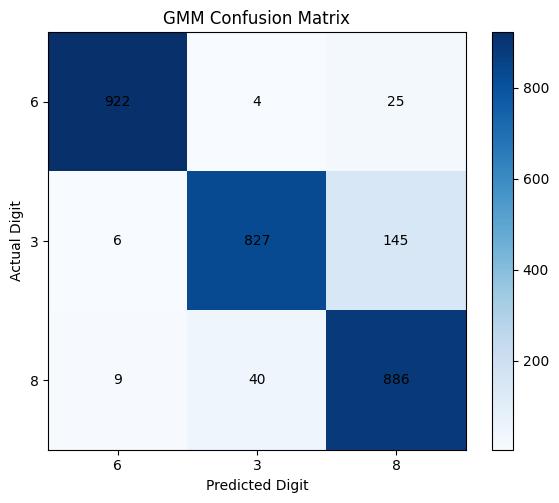

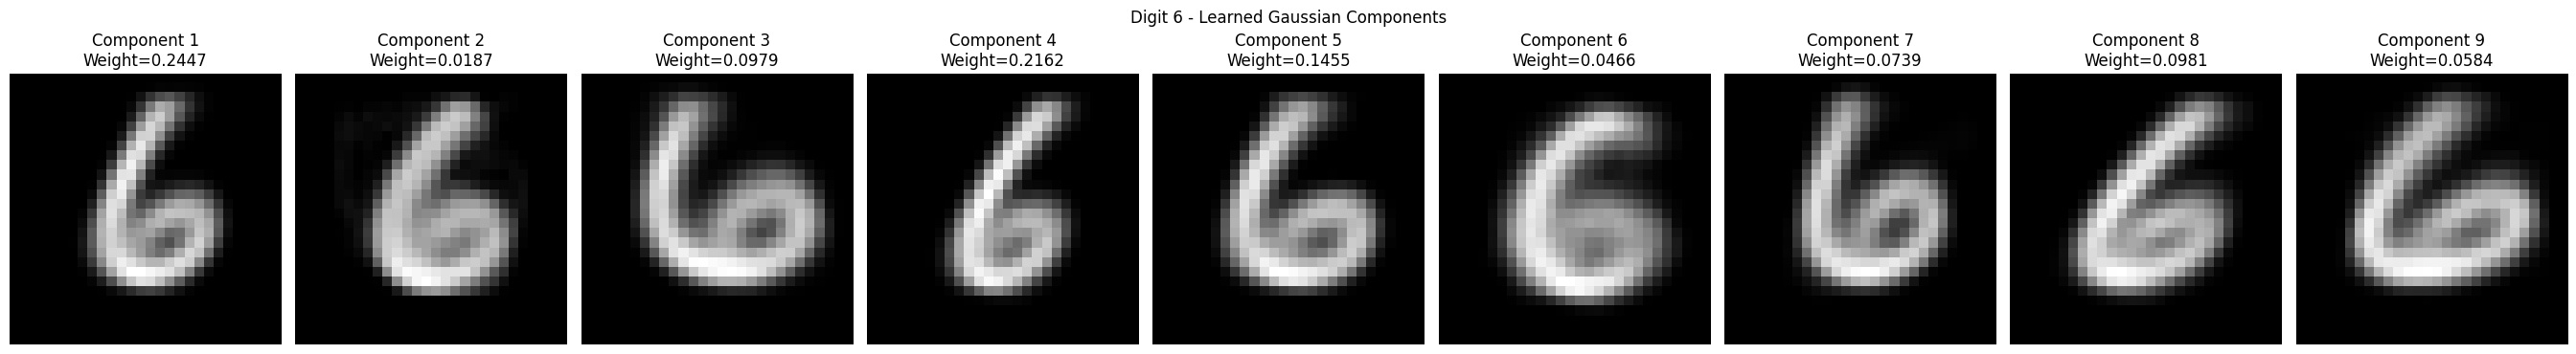

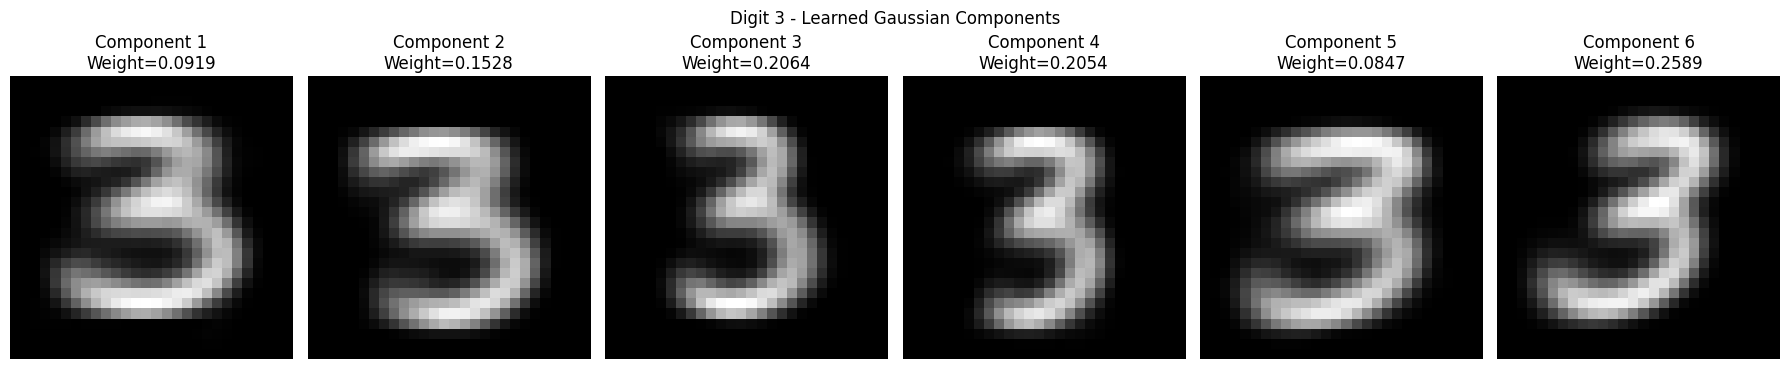

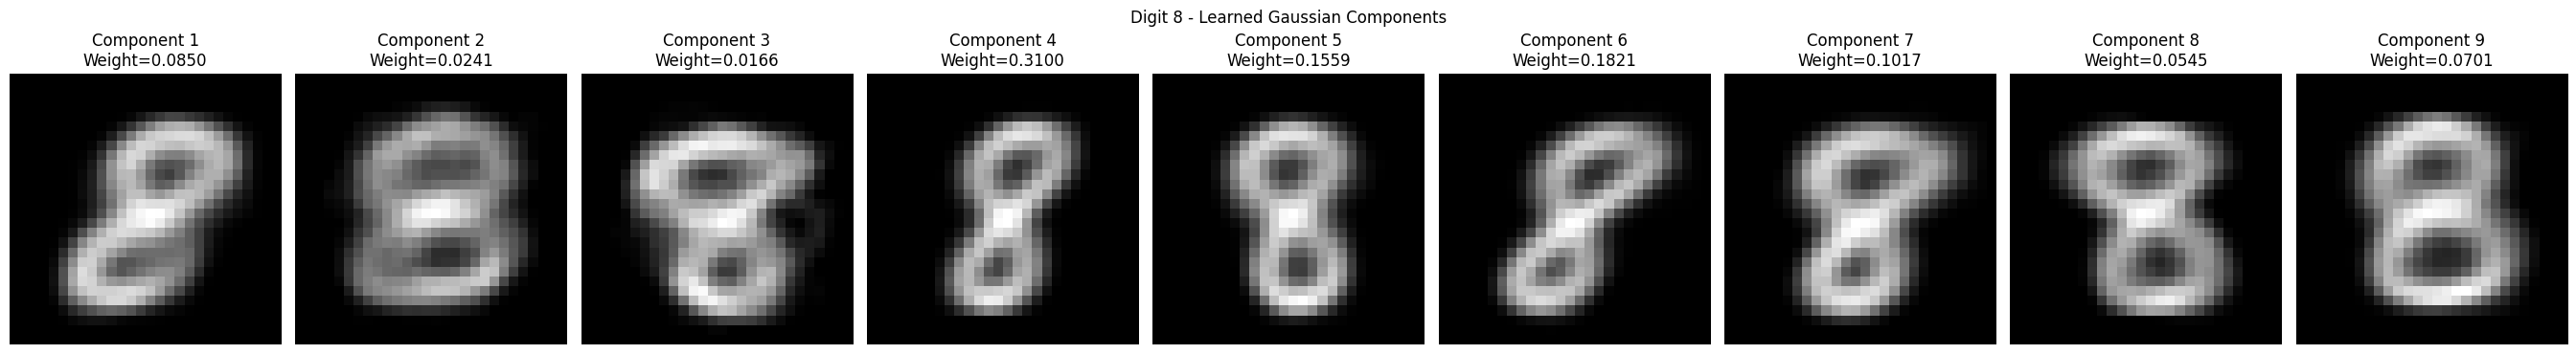


Total Misclassified: 229


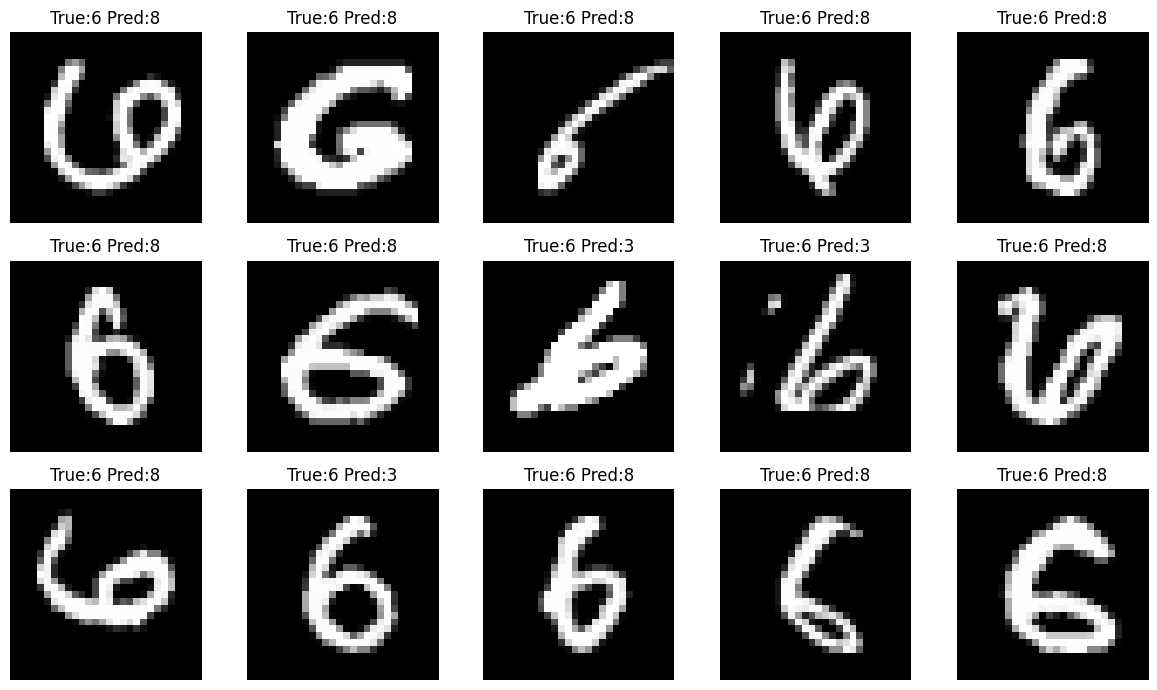


Pairwise Confusion:
Actual 6 predicted as 3: 4
Actual 6 predicted as 8: 25
Actual 3 predicted as 6: 6
Actual 3 predicted as 8: 145
Actual 8 predicted as 6: 9
Actual 8 predicted as 3: 40


In [8]:
cm = np.zeros((len(digits), len(digits)), dtype=int)

for i, actual in enumerate(digits):
    for j, predicted in enumerate(digits):
        cm[i, j] = np.sum(
            (y_test == actual) & (y_pred == predicted)
        )

print("\nConfusion Matrix:")
print(cm)

for i, digit in enumerate(digits):
    tp = cm[i, i]
    precision = tp / max(cm[:, i].sum(), 1)
    recall = tp / max(cm[i, :].sum(), 1)
    f1 = 2 * precision * recall / max(
        precision + recall, eps
    )

    print(
        f"Digit {digit}: Precision={precision:.3f}, "
        f"Recall={recall:.3f}, F1={f1:.3f}"
    )

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')
plt.xticks(range(len(digits)), digits)
plt.yticks(range(len(digits)), digits)
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("GMM Confusion Matrix")

for i in range(len(digits)):
    for j in range(len(digits)):
        plt.text(j, i, str(cm[i, j]),
                 ha='center', va='center')

plt.colorbar()
plt.tight_layout()
plt.show()

for digit in digits:
    weights, means, variances = models[digit]
    K = best_K[digit]

    fig, axes = plt.subplots(1, K, figsize=(3 * K, 4))

    if K == 1:
        axes = [axes]

    fig.suptitle(
        f"Digit {digit} - Learned Gaussian Components"
    )

    for k in range(K):
        axes[k].imshow(
            means[k].reshape(28, 28), cmap='gray'
        )
        axes[k].set_title(
            f"Component {k+1}\nWeight={weights[k]:.4f}"
        )
        axes[k].axis('off')

    plt.tight_layout()
    plt.show()

errors = np.where(y_pred != y_test)[0]

print("\nTotal Misclassified:", len(errors))

if len(errors) > 0:
    count = min(15, len(errors))
    plt.figure(figsize=(12, 7))

    for j, idx in enumerate(errors[:count]):
        plt.subplot(3, 5, j + 1)
        plt.imshow(X_test[idx].reshape(28, 28), cmap='gray')
        plt.title(f"True:{y_test[idx]} Pred:{y_pred[idx]}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

print("\nPairwise Confusion:")

for i, actual in enumerate(digits):
    for j, predicted in enumerate(digits):
        if i != j and cm[i, j] > 0:
            print(
                f"Actual {actual} predicted as {predicted}: "
                f"{cm[i, j]}"
            )
